# BÀI TẬP NÂNG CAO với mô hình SARIMA – Dataset 2 (AirPassengers)

## Bước 3. Sai phân thường (d = 1) + sai phân mùa vụ (D = 1, s = 12)

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
S = 12           # chu kỳ mùa vụ
TEST_SIZE = 24   # 2 năm cuối làm tập kiểm tra

df = pd.read_csv(URL)
df.columns = ["Month", "Passengers"]
df["Month"] = pd.to_datetime(df["Month"])
y = df.set_index("Month")["Passengers"].asfreq("MS")
train, test = y.iloc[:-TEST_SIZE], y.iloc[-TEST_SIZE:]
print(y.shape)
y.head()

(144,)


Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

In [2]:
def adf_test(series, name):
    stat, p, _, _, crit, _ = adfuller(series.dropna(), autolag="AIC")
    print(f"ADF [{name}]: stat = {stat:.4f}, p-value = {p:.4f}, "
          f"crit(5%) = {crit['5%']:.4f} -> "
          f"{'DỪNG' if p < 0.05 else 'KHÔNG DỪNG'}")

In [3]:
y_d1 = y.diff(1)
y_d1_D1 = y.diff(1).diff(S)

adf_test(y, "Chuỗi gốc")
adf_test(y_d1, "Sai phân d=1")
adf_test(y_d1_D1, "Sai phân d=1 và D=1")

ADF [Chuỗi gốc]: stat = 0.8154, p-value = 0.9919, crit(5%) = -2.8840 -> KHÔNG DỪNG
ADF [Sai phân d=1]: stat = -2.8293, p-value = 0.0542, crit(5%) = -2.8840 -> KHÔNG DỪNG
ADF [Sai phân d=1 và D=1]: stat = -15.5956, p-value = 0.0000, crit(5%) = -2.8840 -> DỪNG


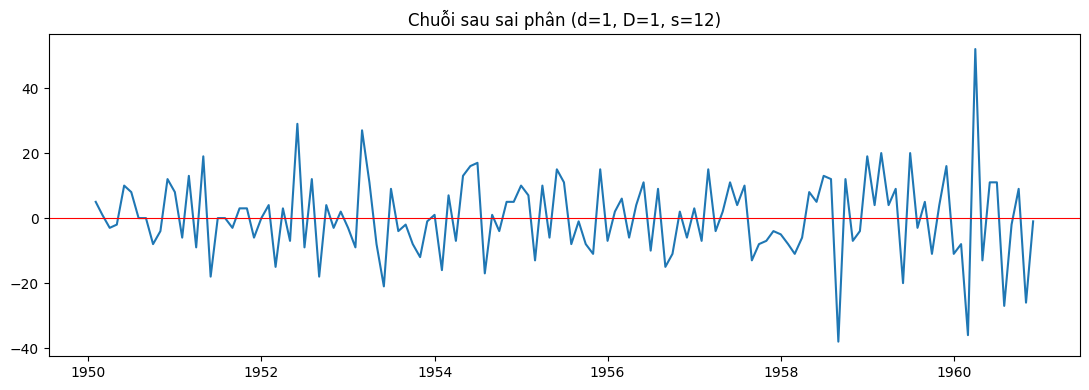

In [4]:
plt.figure(figsize=(11, 4))
plt.plot(y_d1_D1)
plt.axhline(0, color="red", lw=.8)
plt.title("Chuỗi sau sai phân (d=1, D=1, s=12)")
plt.tight_layout(); plt.show()

**Nhận xét:** sau khi sai phân thường (loại trend) và sai phân mùa vụ (loại mùa vụ), kiểm định ADF cho p-value < 0.05 → chuỗi đã **dừng**.